# ♻️ MISSÃO RECOMEÇO
### Desafio 2 · Trilha de Visão Computacional · Olimpíada de IA Aplicada 2026

---

> **"Eu separo material há vinte e dois anos. Sei distinguir os cinco tipos pelo brilho,
> antes mesmo de tocar. A pergunta é se isso que eu sei pode ser descrito com precisão
> suficiente para uma máquina reproduzir."**
>
> — Rosa Bezerra, presidente da Cooperativa Recomeço

---

<img src="https://lh3.googleusercontent.com/d/1Qz9zzwL-EcWPeVBi5_Gz0tc5pOyGoSvm=w1600" width="100%"
     alt="Galpão de cooperativa de reciclagem: Rosa, de lenço colorido no cabelo e luvas verdes, sorri à beira da esteira. Uma câmera sobre tripé, com luz ciano, aponta para as embalagens que passam. Ao fundo, fardos e montanhas de material separado.">


## 📨 O chamado da Cooperativa Recomeço

*A sua equipe recebe um convite para visitar um galpão na periferia da cidade.
Vocês aceitam. E o que encontram lá muda a forma como vocês olham para o lixo.*

---

**De:** Cooperativa Recomeço · Setor de Triagem
**Para:** Equipe de Engenharia de Visão Computacional

> Presido uma cooperativa com 34 associados. Recebemos cerca de seis toneladas diárias de
> material misto, separadas manualmente peça por peça.
>
> O problema é econômico e mensurável. Lotes com contaminação, por exemplo vidro
> particulado misturado ao papel, são desclassificados na venda e reduzem drasticamente a
> receita do mês. A taxa de erro na triagem manual cresce ao longo do turno, por fadiga.
>
> Fomos procurados por um grupo da universidade que sugeriu classificação automática por
> imagem. Não domino a técnica, mas domino o material, e talvez seja aí que eu possa
> contribuir com vocês.
>
> **Cada material tem uma assinatura óptica distinta.** O papel é fosco, de reflexão
> difusa. O papelão também é fosco, mas é mais escuro e tem textura de ondulação. O
> plástico tem cor saturada e superfície regular. O vidro é parcialmente translúcido e
> produz reflexos concentrados. O metal tem reflexão especular intensa, quase sempre em
> faixas.
>
> Reparem que eu acabei de descrever, com as palavras que tenho, propriedades que são
> mensuráveis. Suspeito que seja exatamente isso que vocês precisam extrair.
>
> Instalamos uma câmera sobre a esteira e registramos alguns milhares de imagens,
> rotuladas por tipo. **Aviso que as condições não são de laboratório:** a iluminação do
> galpão varia ao longo do dia e o material chega sujo. É o dado real que temos.
>
> Duas advertências. **Papel e papelão são a dupla que mais confunde**, inclusive gente
> experiente. E os cinco tipos não chegam em quantidades iguais: entra bem mais papel do
> que papelão, e isso é a nossa rotina, não um defeito da amostra.
>
> — Rosa Bezerra

---

*As observações finais da mensagem não são detalhes. Elas definem a dificuldade do problema.*


## 🎯 A sua missão

Construir um modelo de IA que **olha uma foto de um material** e diz se é
**papel**, **papelão**, **plástico**, **vidro** ou **metal**.

### O problema da representação

Uma imagem digital é uma matriz de intensidades: cada pixel guarda três valores, um por
canal de cor. Uma imagem de 48 por 48 pixels contém, portanto, 6.912 valores. Entregar essa
matriz bruta a um classificador clássico é inviável por dois motivos: a dimensionalidade é
alta demais em relação ao número de exemplos disponíveis, e a representação por pixel é
frágil, já que qualquer deslocamento do objeto altera completamente o vetor.

A alternativa clássica, e a que este desafio adota, é a **extração de características**:
substituir os milhares de valores brutos por um conjunto pequeno de medidas que descrevem
propriedades globais da imagem, como brilho médio, contraste, saturação, densidade de
bordas e proporção de área com alta luminância.

Reparem no que a Rosa fez na mensagem. Ao descrever reflexão difusa, saturação e reflexo
especular, ela enunciou, em linguagem natural, um conjunto de descritores. **Conhecimento
de domínio é o que orienta a escolha das características**, e é por isso que projetos de IA
aplicada dão errado quando a equipe técnica não conversa com quem entende do problema.

> Consequência prática: depois da extração, cada imagem passa a ser uma linha de uma
> tabela, e o problema se reduz a uma classificação tabular convencional. Os mesmos
> algoritmos e a mesma interface do desafio anterior voltam a valer.

### 🗺️ O mapa da missão

| Bloco | O que vocês fazem | Como |
|:---|:---|:---|
| **1 · EXPLORAR** | Ver as fotos da esteira e descobrir o que separa cada material | Só clicando |
| **2 · CONFIGURAR** | Decidir quais características usar e como treinar | Só arrastando |
| **3 · MODELAR** | Ensinar o modelo a enxergar | ✏️ Completando o código |
| **4 · AVALIAR** | Descobrir onde o modelo se confunde, e por quê | Só clicando |

> ⚠️ Confirme que o ambiente está em **CPU** (`Ambiente de execução` → `Alterar o tipo`).
> Não usamos rede neural pesada aqui: nosso modelo roda em **segundos**, e mesmo assim
> aprende muito bem. Inteligência não é sinônimo de peso.


In [32]:
#@title 🛠️ Preparação: recebendo as fotos da esteira { display-mode: "form" }
# Endereços oficiais dos dados. A organização republica aqui se precisar trocar.
URL_TREINO_FOTOS = "https://drive.google.com/uc?export=download&id=1lJRXzTupXGUrn3R6tdnA7ulROYEEe7RX"
URL_TESTE_FOTOS = "https://drive.google.com/uc?export=download&id=10gpTF72qwQ7a15Q-ZruntCnlB59RPSGD"

import pathlib, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

CLASSES = ["papel", "papelao", "plastico", "vidro", "metal"]
EMOJI   = {"papel":"📄", "papelao":"📦", "plastico":"🧴", "vidro":"🍾", "metal":"🥫"}


def extrair_caracteristicas(fotos):
    """👀 Transforma cada FOTO em uma LINHA DE NÚMEROS que o modelo entende."""
    L = []
    for im in fotos:
        cinza = im.mean(axis=2)
        gx = np.abs(np.diff(cinza, axis=1)).mean()
        gy = np.abs(np.diff(cinza, axis=0)).mean()
        mx, mn = im.max(axis=2), im.min(axis=2)
        satur  = np.where(mx > 0, (mx - mn) / (mx + 1e-6), 0)
        L.append([im[...,0].mean(), im[...,1].mean(), im[...,2].mean(),
                  im[...,0].std(),  im[...,1].std(),  im[...,2].std(),
                  cinza.mean(), cinza.std(), np.percentile(cinza, 95),
                  np.percentile(cinza, 95) - np.percentile(cinza, 5),
                  (gx + gy) / 2, satur.mean(), satur.std(),
                  (cinza > .80).mean()])
    return pd.DataFrame(L, columns=[
        "vermelho_medio","verde_medio","azul_medio",
        "vermelho_variacao","verde_variacao","azul_variacao",
        "brilho_medio","contraste","brilho_alto",
        "amplitude_luz","bordas","saturacao_media","saturacao_variacao","area_reluzente"])


def _npz(url, nome_local):
    """Baixa do endereço oficial; sem endereço ou sem rede, pede o envio."""
    if url and not pathlib.Path(nome_local).exists():
        import urllib.request
        try:
            print(f"Baixando {nome_local}...")
            urllib.request.urlretrieve(url, nome_local)
        except Exception as erro:
            print(f"  não deu certo ({erro.__class__.__name__}).")
    if not pathlib.Path(nome_local).exists():
        from google.colab import files
        print(f"Envie o arquivo {nome_local}:")
        files.upload()
    return np.load(nome_local, allow_pickle=False)


# As fotos vêm em uint8 (0-255), como qualquer imagem; o modelo trabalha em [0,1].
_treino = _npz(URL_TREINO_FOTOS, "treino_fotos.npz")
_teste = _npz(URL_TESTE_FOTOS, "teste_fotos.npz")

# Conjunto PÚBLICO: rotulado. Serve para treinar e validar.
fotos = _treino["fotos"].astype(np.float32) / 255.0
rotulos = _treino["rotulos"]

# Conjunto de TESTE: tamanho fixo, rótulos ocultos. Base da comparação oficial.
fotos_teste = _teste["fotos"].astype(np.float32) / 255.0
N_TESTE = len(fotos_teste)

print("Ambiente carregado.")
print(f"  Conjunto público (rotulado) ....... {len(fotos):>4} imagens, {len(CLASSES)} materiais")
print(f"  Conjunto de teste (sem rótulo) .... {len(fotos_teste):>4} imagens  [tamanho fixo]")
print(f"  Cada imagem: {fotos.shape[1]}x{fotos.shape[2]} pixels x 3 canais = "
      f"{fotos.shape[1]*fotos.shape[2]*3:,} valores")
print(f"\n  A submissão precisará ter exatamente {N_TESTE} linhas.")
print("\n   A etapa seguinte reduz essa representação a um conjunto pequeno")
print("   de descritores com poder discriminante.")

Ambiente carregado.
  Conjunto público (rotulado) ....... 2150 imagens, 5 materiais
  Conjunto de teste (sem rótulo) ....  240 imagens  [tamanho fixo]
  Cada imagem: 48x48 pixels x 3 canais = 6,912 valores

  A submissão precisará ter exatamente 240 linhas.

   A etapa seguinte reduz essa representação a um conjunto pequeno
   de descritores com poder discriminante.


---
# 🔍 BLOCO 1 · EXPLORAR
## *Olhem com os olhos da Dona Rosa*

> **Rosa:** *"Antes de programar qualquer coisa, olhem o material. Vocês precisam
> conseguir descrever a diferença antes de tentar medi-la."*

Cada propriedade que vocês conseguirem verbalizar nesta etapa corresponde a um descritor
que pode ser calculado. A qualidade da representação depende dessa observação inicial.


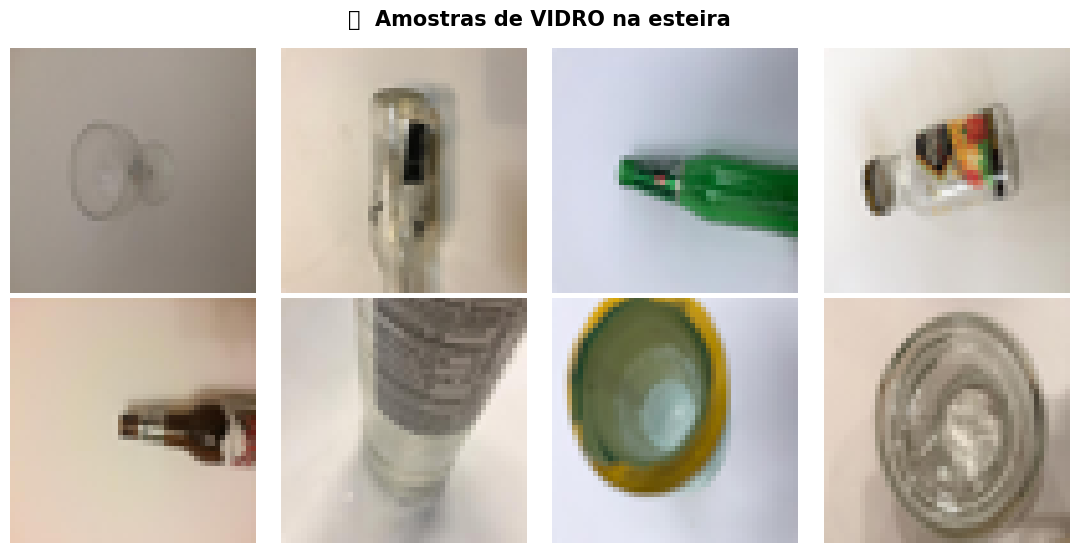

Analisem as amostras de VIDRO sob quatro dimensões:
   Luminância    - a superfície é clara ou escura, e quão uniforme é?
   Saturação     - a cor é intensa ou próxima do acromático?
   Reflectância  - a reflexão é difusa (espalhada) ou especular (concentrada)?
   Textura       - há variação local de intensidade ou a superfície é homogênea?

Alternem entre os materiais e registrem quais dimensões os separam melhor.
Essa análise antecipa quais descritores terão poder discriminante.


In [33]:
#@title 📷 As fotos da esteira { display-mode: "form" }
#@markdown Escolha um material e rode a célula (▶) para ver oito fotos dele.
material = "vidro"  #@param ["papel", "papelao", "plastico", "vidro", "metal"]

idx = np.where(rotulos == material)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(fotos[i]); ax.axis("off")
fig.suptitle(f"{EMOJI[material]}  Amostras de {material.upper()} na esteira",
             fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Analisem as amostras de {material.upper()} sob quatro dimensões:")
print("   Luminância    - a superfície é clara ou escura, e quão uniforme é?")
print("   Saturação     - a cor é intensa ou próxima do acromático?")
print("   Reflectância  - a reflexão é difusa (espalhada) ou especular (concentrada)?")
print("   Textura       - há variação local de intensidade ou a superfície é homogênea?")
print("\nAlternem entre os materiais e registrem quais dimensões os separam melhor.")
print("Essa análise antecipa quais descritores terão poder discriminante.")

In [34]:
#@title 🔢 Extração de características: de imagem para vetor { display-mode: "form" }
# Esta célula transforma **todas as fotos** em uma tabela de características.
# É o passo que faz um problema de imagem virar um problema de tabela.
X_caract = extrair_caracteristicas(fotos)
X_caract_teste = extrair_caracteristicas(fotos_teste)

print("Extração concluída.\n")
print(f"   Representação bruta:    {fotos.shape[1]*fotos.shape[2]*3:,} valores por imagem")
print(f"   Representação extraída: {X_caract.shape[1]} valores por imagem\n")
tabela = X_caract.copy(); tabela.insert(0, "material", rotulos)
display(tabela.head())
print("\nO objeto resultante é uma tabela convencional. O problema de visão foi")
print("reduzido a um problema tabular, e assim será tratado daqui em diante.")

Extração concluída.

   Representação bruta:    6,912 valores por imagem
   Representação extraída: 14 valores por imagem



,material,vermelho_medio,verde_medio,azul_medio,vermelho_variacao,verde_variacao,azul_variacao,brilho_medio,contraste,brilho_alto,amplitude_luz,bordas,saturacao_media,saturacao_variacao,area_reluzente
0,metal,0.533264,0.488542,0.420016,0.152371,0.158257,0.172631,0.480607,0.159451,0.683660,0.488889,0.035496,0.247679,0.167356,0.031684
1,papel,0.755886,0.746572,0.728345,0.161172,0.173827,0.185952,0.743601,0.173351,0.903268,0.521177,0.056825,0.052220,0.065074,0.586372
2,papelao,0.708429,0.649215,0.561417,0.180570,0.188570,0.195047,0.639687,0.181680,0.877124,0.580196,0.047042,0.227002,0.163629,0.154948
3,papel,0.778048,0.742793,0.699088,0.105302,0.081849,0.089520,0.739977,0.089712,0.841830,0.243137,0.010284,0.118343,0.062452,0.320312
4,vidro,0.591457,0.554065,0.516828,0.057658,0.057403,0.057752,0.554117,0.057538,0.627451,0.180392,0.005611,0.127454,0.016721,0.000000



O objeto resultante é uma tabela convencional. O problema de visão foi
reduzido a um problema tabular, e assim será tratado daqui em diante.


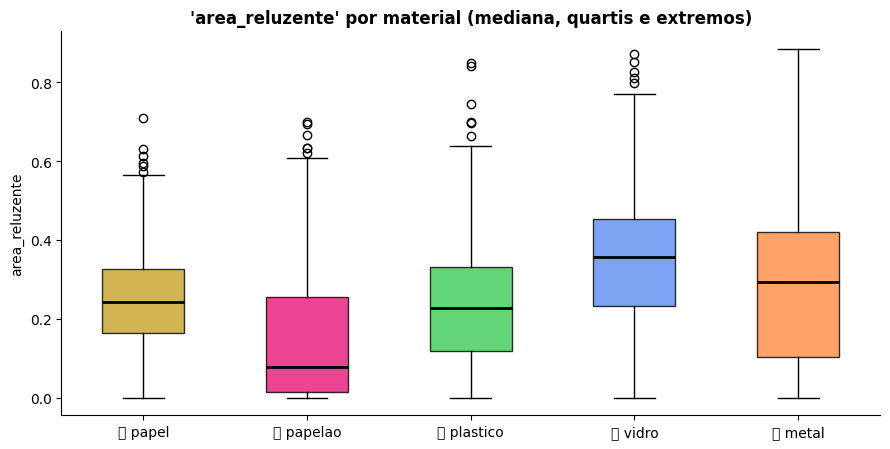

Média de 'area_reluzente':
   📄 papel     0.249
   📦 papelao   0.152
   🧴 plastico  0.229
   🍾 vidro     0.333
   🥫 metal     0.288

Amplitude entre classes: 0.182
   Observem também a SOBREPOSIÇÃO entre as distribuições: classes com médias
   distantes mas grande dispersão continuam difíceis de separar por essa
   variável isoladamente. Nenhum descritor precisa separar tudo sozinho.

SUGESTÃO: use a Dispersão para cruzar dois descritores e procurar pares que
   separem classes que um descritor sozinho não separa.


In [35]:
#@title 📊 Investigue os descritores: escolha a variável E o tipo de gráfico { display-mode: "form" }
#@markdown Escolha o descritor e o gráfico, depois rode a célula (▶).
caracteristica = "area_reluzente"  #@param ["vermelho_medio", "verde_medio", "azul_medio", "vermelho_variacao", "verde_variacao", "azul_variacao", "brilho_medio", "contraste", "brilho_alto", "amplitude_luz", "bordas", "saturacao_media", "saturacao_variacao", "area_reluzente"]
tipo_de_grafico = "Boxplot"  #@param ["Boxplot", "Histograma sobreposto", "Violino", "Barras de media", "Dispersao contra outro descritor", "Galeria por faixa do descritor"]
segundo_descritor = "area_reluzente"  #@param ["vermelho_medio", "verde_medio", "azul_medio", "brilho_medio", "contraste", "bordas", "saturacao_media", "area_reluzente", "amplitude_luz"]

CORES_G = ["#C9A227", "#E6177A", "#3DCB55", "#5B8DEF", "#FF8C42"]
grupos = [X_caract[rotulos == c][caracteristica] for c in CLASSES]
rot_leg = [f"{EMOJI[c]} {c}" for c in CLASSES]

fig, ax = plt.subplots(figsize=(9, 4.6))

if tipo_de_grafico == "Boxplot":
    bp = ax.boxplot(grupos, patch_artist=True, tick_labels=rot_leg,
                    medianprops=dict(color="black", linewidth=2))
    for p, c in zip(bp["boxes"], CORES_G): p.set_facecolor(c); p.set_alpha(.8)
    ax.set_ylabel(caracteristica)
    ax.set_title(f"'{caracteristica}' por material (mediana, quartis e extremos)", fontweight="bold")

elif tipo_de_grafico == "Histograma sobreposto":
    bins = np.histogram_bin_edges(X_caract[caracteristica], bins=28)
    for g, c, r in zip(grupos, CORES_G, CLASSES):
        ax.hist(g, bins=bins, alpha=.55, label=r, color=c, edgecolor="white")
    ax.legend(); ax.set_xlabel(caracteristica); ax.set_ylabel("quantidade")
    ax.set_title(f"Distribuição de '{caracteristica}' por material", fontweight="bold")

elif tipo_de_grafico == "Violino":
    vp = ax.violinplot(grupos, showmedians=True)
    for corpo, c in zip(vp["bodies"], CORES_G): corpo.set_facecolor(c); corpo.set_alpha(.75)
    ax.set_xticks(range(1, len(CLASSES) + 1)); ax.set_xticklabels(rot_leg)
    ax.set_ylabel(caracteristica)
    ax.set_title(f"Densidade de '{caracteristica}' por material", fontweight="bold")

elif tipo_de_grafico == "Barras de media":
    med = [g.mean() for g in grupos]; err = [g.std()/np.sqrt(len(g)) for g in grupos]
    ax.bar(rot_leg, med, yerr=err, capsize=7, color=CORES_G, edgecolor="#1F2A44")
    ax.set_ylabel(f"média de {caracteristica}")
    ax.set_title(f"Média de '{caracteristica}' por material (barra = erro padrão)", fontweight="bold")

elif tipo_de_grafico == "Dispersao contra outro descritor":
    for c, cor in zip(CLASSES, CORES_G):
        sub = X_caract[rotulos == c]
        ax.scatter(sub[caracteristica], sub[segundo_descritor], s=16, alpha=.6,
                   color=cor, label=c, edgecolors="none")
    ax.set_xlabel(caracteristica); ax.set_ylabel(segundo_descritor); ax.legend()
    ax.set_title(f"'{caracteristica}' contra '{segundo_descritor}'", fontweight="bold")

else:  # Galeria por faixa
    plt.close(fig)
    ordem = np.argsort(X_caract[caracteristica].values)
    baixos, altos = ordem[:5], ordem[-5:]
    fig, axes = plt.subplots(2, 5, figsize=(11.5, 5))
    for linha, grupo in ((0, baixos), (1, altos)):
        for ax_, i in zip(axes[linha], grupo):
            ax_.imshow(fotos[i]); ax_.axis("off")
            ax_.set_title(f"{rotulos[i]}\n{X_caract[caracteristica].iloc[i]:.3f}", fontsize=8)
    fig.suptitle(f"Imagens com os MENORES (acima) e MAIORES (abaixo) valores de "
                 f"'{caracteristica}'", fontweight="bold")
    plt.tight_layout(); plt.show()
    print("Esta visualização conecta o número à imagem: vejam o que de fato muda")
    print(f"na aparência do material entre os extremos de '{caracteristica}'.")
    print("É a forma mais direta de verificar se um descritor mede o que vocês supõem.")

if tipo_de_grafico != "Galeria por faixa do descritor":
    ax.spines[["top","right"]].set_visible(False)
    plt.tight_layout(); plt.show()
    m = pd.Series({c: X_caract[rotulos == c][caracteristica].mean() for c in CLASSES})
    print(f"Média de '{caracteristica}':")
    for c in CLASSES: print(f"   {EMOJI[c]} {c:<9} {m[c]:.3f}")
    print(f"\nAmplitude entre classes: {m.max()-m.min():.3f}")
    print("   Observem também a SOBREPOSIÇÃO entre as distribuições: classes com médias")
    print("   distantes mas grande dispersão continuam difíceis de separar por essa")
    print("   variável isoladamente. Nenhum descritor precisa separar tudo sozinho.")
    print("\nSUGESTÃO: use a Dispersão para cruzar dois descritores e procurar pares que")
    print("   separem classes que um descritor sozinho não separa.")

> **Rosa:** *"A reflexão especular do metal aparece nos números de vocês. Era o que eu
> esperava. O difícil vai ser o vidro."*

<img src="https://lh3.googleusercontent.com/d/1SEXPNOB_d56gI0Ixd3ws5l0x5x-RhLRf=w1600" width="100%"
     alt="Cena dividida ao meio: à esquerda, uma lata de alumínio amassada sobre a esteira; à direita, a mesma lata redesenhada como uma grade luminosa de números, dígitos binários e histogramas. Feixes de luz ciano ligam os dois lados.">


---
# ⚙️ BLOCO 2 · CONFIGURAR
## *As decisões que definem o desempenho*

### Como os dados estão organizados

| Conjunto | Tamanho | Vocês têm os rótulos? | Para que serve |
|:---|:---|:---|:---|
| **Público** | 2.150 imagens | Sim | Treinar o modelo e validar as escolhas |
| **Teste** | **240 (fixo)** | Não | Comparação oficial entre todas as equipes |

O controle abaixo define que fatia do conjunto público fica reservada para **validação**.
O conjunto de teste tem tamanho fixo e igual para todas as equipes, e a submissão precisa
ter exatamente 240 linhas.


In [36]:
#@title Etapas 0.1–0.4: configuração fixa do baseline
# Nesta fase, não selecionar/remover descritores nem criar novas features.
SEMENTE = 42
tamanho_da_validacao = 20
N_JOBS_BUSCA = -1  # -1 usa os núcleos disponíveis; use 1 em ambientes restritos.
conjunto_de_caracteristicas = "todas"
colunas = list(X_caract.columns)

print("BASELINE COM AS FEATURES ORIGINAIS")
print(f"Descritores: {len(colunas)} (todos os originais)")
print(f"Treino/validação: {100-tamanho_da_validacao}%/{tamanho_da_validacao}%")
print(f"Semente: {SEMENTE}; CV estratificada: 5 partes")
print("Modelos: SVM, Regressão Logística e Random Forest")
print("Métrica da busca: F1-macro; nenhuma feature nova até a etapa 0.4.")


BASELINE COM AS FEATURES ORIGINAIS
Descritores: 14 (todos os originais)
Treino/validação: 80%/20%
Semente: 42; CV estratificada: 5 partes
Modelos: SVM, Regressão Logística e Random Forest
Métrica da busca: F1-macro; nenhuma feature nova até a etapa 0.4.


### Seleção de descritores e padronização

**Seleção de características.** Fornecer todos os descritores nem sempre maximiza o
desempenho. Variáveis com baixo poder discriminante adicionam ruído ao espaço de entrada.
Restringir o conjunto é uma forma de regularização.

**Padronização.** Os descritores têm escalas distintas. Modelos que operam sobre
distâncias, como o SVM, ou que dependem de otimização por gradiente, como a regressão
logística, são sensíveis a essa disparidade: variáveis de maior amplitude dominam a função
objetivo independentemente de sua relevância. Modelos baseados em árvores são invariantes a
transformações monotônicas e não se beneficiam disso.

---

### 📗 Referência técnica: nome exato e parâmetros de cada classe

**Vocês vão precisar desta tabela no Bloco 3.**

> **Por que isso importa.** No Bloco 3, apenas alguns parâmetros aparecem preenchidos.
> Todos os demais assumem silenciosamente o valor padrão. Completar só o nome da classe
> produz um resultado correto e mediano. Estudar esta tabela e **acrescentar parâmetros
> à chamada** produz resultados consistentemente melhores. A diferença é intencional.

#### 🔧 Padronizador

```python
from sklearn.preprocessing import StandardScaler
```

| Parâmetro | Padrão | O que faz |
|:---|:---|:---|
| `with_mean` | `True` | Subtrai a média de cada variável |
| `with_std` | `True` | Divide pelo desvio-padrão |
| `copy` | `True` | Se opera sobre uma cópia dos dados |

#### 📈 Regressão Logística

```python
from sklearn.linear_model import LogisticRegression
```

| Parâmetro | Padrão | O que faz |
|:---|:---|:---|
| `penalty` | `'l2'` | Tipo de regularização. Aceita `'l1'`, `'l2'`, `'elasticnet'`, `None` |
| `C` | `1.0` | Inverso da força da regularização. **Menor regulariza mais** |
| `solver` | `'lbfgs'` | Algoritmo de otimização |
| `max_iter` | `100` | Iterações máximas. Frequentemente insuficiente |
| `class_weight` | `None` | `'balanced'` compensa desbalanceamento |
| `multi_class` | automático | Estratégia para mais de duas classes |
| `random_state` | `None` | Semente |

#### 🌲 Floresta Aleatória

```python
from sklearn.ensemble import RandomForestClassifier
```

| Parâmetro | Padrão | O que faz |
|:---|:---|:---|
| `n_estimators` | `100` | Número de árvores |
| `max_depth` | `None` | Profundidade máxima |
| `min_samples_leaf` | `1` | Mínimo de amostras por folha. Aumentar suaviza |
| `max_features` | `'sqrt'` | Variáveis sorteadas por corte. Aceita fração |
| `class_weight` | `None` | `'balanced'` ou `'balanced_subsample'` |
| `criterion` | `'gini'` | Alternativa: `'entropy'` |
| `n_jobs` | `None` | `-1` usa todos os núcleos |
| `random_state` | `None` | Semente |

#### 🎯 SVM

```python
from sklearn.svm import SVC
```

| Parâmetro | Padrão | O que faz |
|:---|:---|:---|
| `C` | `1.0` | Penalidade por erro. **Maior ajusta mais aos dados de treino** |
| `kernel` | `'rbf'` | Aceita `'linear'`, `'poly'`, `'rbf'`, `'sigmoid'` |
| `gamma` | `'scale'` | Alcance de influência de cada exemplo. Aceita `'auto'` ou número |
| `degree` | `3` | Grau, quando `kernel='poly'` |
| `class_weight` | `None` | `'balanced'` compensa desbalanceamento |
| `probability` | `False` | Habilita `predict_proba`, ao custo de tempo |
| `random_state` | `None` | Semente |

> 💡 No SVM, **`C` e `gamma` interagem**. Aumentar `C` sem controlar `gamma` costuma levar
> a sobreajuste. Vale testar combinações e comparar na validação.


---
# ✏️ BLOCO 3 · BASELINE — etapas 0.1 a 0.5 do plano

Usamos somente os **14 descritores originais**, sem alterar o extrator ou as imagens.

A divisão estratificada é única: **80% treino / 20% validação**, com semente 42.
A busca de hiperparâmetros usa os mesmos cinco folds **dentro do treino**.
O `StandardScaler` fica dentro dos pipelines de SVM e Regressão Logística,
sendo ajustado novamente apenas no treino de cada fold. Random Forest não é padronizado.

Primeiro registramos os três modelos sem busca (0.2). Depois executamos as grades
do plano (0.3–0.4) com `scoring="f1_macro"`. O baseline é escolhido pelo maior
F1-macro de validação, conforme o plano. Essa validação participa da escolha do
modelo: seu resultado não é uma estimativa independente pós-seleção.

**Baseline até a etapa 0.5.** Após a seleção do baseline, analisamos
a importância das features sem removê-las. Em seguida, E1 testa uma única candidata
seguindo 0.6–0.10. ROI e demais descritores ficam para depois.


In [37]:
#@title Etapa 0.1 — features originais e divisão única
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedKFold
from sklearn.pipeline import Pipeline

COLUNAS_ORIGINAIS = (
    "vermelho_medio", "verde_medio", "azul_medio",
    "vermelho_variacao", "verde_variacao", "azul_variacao",
    "brilho_medio", "contraste", "brilho_alto", "amplitude_luz",
    "bordas", "saturacao_media", "saturacao_variacao", "area_reluzente",
)
X_original = X_caract.loc[:, COLUNAS_ORIGINAIS].copy()
y = rotulos.copy()
assert tuple(X_caract.columns) == COLUNAS_ORIGINAIS
assert len(X_original) == len(y) and np.isfinite(X_original.to_numpy()).all()
colunas = list(COLUNAS_ORIGINAIS)
X = X_original

X_treino, X_valida, y_treino, y_valida = train_test_split(
    X_original, y, test_size=tamanho_da_validacao/100,
    random_state=SEMENTE, stratify=y,
)
# Índices originais preservados para reutilizar exatamente esta divisão depois.
indices_treino = X_treino.index.to_numpy(copy=True)
indices_validacao = X_valida.index.to_numpy(copy=True)
assert not set(indices_treino).intersection(indices_validacao)
assert len(indices_treino) + len(indices_validacao) == len(X_original)

cv_baseline = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
folds_cv_baseline = list(cv_baseline.split(X_treino, y_treino))
# Os índices dos folds são posicionais e se referem somente a X_treino.
for treino_fold, valida_fold in folds_cv_baseline:
    assert not set(treino_fold).intersection(valida_fold)
    assert set(indices_treino[valida_fold]).isdisjoint(indices_validacao)

print(f"X_original: {X_original.shape}; treino: {len(y_treino)}; validação: {len(y_valida)}")
display(pd.DataFrame({
    "Treino": pd.Series(y_treino).value_counts(),
    "Validação": pd.Series(y_valida).value_counts(),
}).reindex(CLASSES))


X_original: (2150, 14); treino: 1720; validação: 430


,Treino,Validação
papel,427,107
papelao,290,72
plastico,347,87
vidro,361,90
metal,295,74


In [38]:
#@title Etapa 0.2 — treinar e avaliar os três modelos iniciais
def avaliar_baseline(estimador, X_avaliacao, y_avaliacao):
    pred = estimador.predict(X_avaliacao)
    return {
        "previsoes": pred,
        "f1_macro": f1_score(y_avaliacao, pred, average="macro", zero_division=0),
        "acuracia": accuracy_score(y_avaliacao, pred),
        "f1_por_classe": pd.Series(
            f1_score(y_avaliacao, pred, labels=CLASSES, average=None, zero_division=0),
            index=CLASSES, name="F1",
        ),
        "matriz_confusao": pd.DataFrame(
            confusion_matrix(y_avaliacao, pred, labels=CLASSES),
            index=pd.Index(CLASSES, name="Real"),
            columns=pd.Index(CLASSES, name="Previsto"),
        ),
    }

modelos_iniciais = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=1.0, kernel="rbf", random_state=SEMENTE)),
    ]),
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=1.0, max_iter=3000, random_state=SEMENTE)),
    ]),
    # n_jobs=1 no estimador evita paralelismo aninhado durante o GridSearchCV.
    "Random Forest": RandomForestClassifier(
        n_estimators=250, random_state=SEMENTE, n_jobs=1,
    ),
}
modelos_iniciais_ajustados = {}
metricas_iniciais = {}
for nome, estimador in modelos_iniciais.items():
    ajustado = clone(estimador).fit(X_treino, y_treino)
    modelos_iniciais_ajustados[nome] = ajustado
    metricas_iniciais[nome] = avaliar_baseline(ajustado, X_valida, y_valida)

comparacao_inicial = pd.DataFrame([
    {"Modelo": nome, "F1 validação": m["f1_macro"], "Acurácia": m["acuracia"]}
    for nome, m in metricas_iniciais.items()
]).sort_values("F1 validação", ascending=False, kind="stable").reset_index(drop=True)
print("Modelos iniciais, antes da busca de hiperparâmetros:")
display(comparacao_inicial.round(4))
f1_por_classe_inicial = pd.DataFrame({
    nome: m["f1_por_classe"] for nome, m in metricas_iniciais.items()
})
print("F1 por classe — modelos iniciais:")
display(f1_por_classe_inicial.round(4))
for nome, m in metricas_iniciais.items():
    print(f"Matriz de confusão inicial — {nome} (linhas = real; colunas = previsto):")
    display(m["matriz_confusao"])


Modelos iniciais, antes da busca de hiperparâmetros:


,Modelo,F1 validação,Acurácia
0,SVM,0.6819,0.6860
1,Random Forest,0.6790,0.6860
2,Regressão Logística,0.5877,0.6023


F1 por classe — modelos iniciais:


,SVM,Regressão Logística,Random Forest
papel,0.7632,0.6721,0.7632
papelao,0.7385,0.7273,0.6977
plastico,0.7086,0.6486,0.6780
vidro,0.5979,0.5111,0.6630
metal,0.6015,0.3793,0.5931


Matriz de confusão inicial — SVM (linhas = real; colunas = previsto):


Previsto,papel,papelao,plastico,vidro,metal
Real,,,,,
papel,87,2,3,9,6
papelao,7,48,4,10,3
plastico,9,5,62,7,4
vidro,9,2,15,58,6
metal,9,1,4,20,40


Matriz de confusão inicial — Regressão Logística (linhas = real; colunas = previsto):


Previsto,papel,papelao,plastico,vidro,metal
Real,,,,,
papel,83,0,9,8,7
papelao,9,48,5,8,2
plastico,15,4,60,6,2
vidro,15,5,15,46,9
metal,18,3,9,22,22


Matriz de confusão inicial — Random Forest (linhas = real; colunas = previsto):


Previsto,papel,papelao,plastico,vidro,metal
Real,,,,,
papel,87,3,3,7,7
papelao,8,45,5,8,6
plastico,11,4,60,5,7
vidro,7,2,13,60,8
metal,8,3,9,11,43


In [39]:
#@title Etapa 0.3 — grades de hiperparâmetros dos três modelos
# Prefixo model__ identifica o classificador dentro do Pipeline.
grades_baseline = {
    "SVM": {
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", "auto", 0.01, 0.1],
        "model__kernel": ["rbf"],
        "model__class_weight": [None, "balanced"],
    },
    "Regressão Logística": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "n_estimators": [200, 400],
        "max_depth": [None, 8, 15],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", "log2"],
        "class_weight": [None, "balanced"],
    },
}
for nome, grade in grades_baseline.items():
    quantidade = len(ParameterGrid(grade))
    print(f"{nome}: {quantidade} combinações, {quantidade*len(folds_cv_baseline)} ajustes de CV")
print("Grades completas do plano; a busca de Random Forest pode demorar vários minutos.")


SVM: 32 combinações, 160 ajustes de CV
Regressão Logística: 10 combinações, 50 ajustes de CV
Random Forest: 144 combinações, 720 ajustes de CV
Grades completas do plano; a busca de Random Forest pode demorar vários minutos.


In [40]:
#@title Etapa 0.4 — GridSearchCV otimizado por F1-macro
from time import perf_counter

buscas_baseline = {}
metricas_otimizadas = {}
linhas_comparacao = []
for nome, estimador in modelos_iniciais.items():
    inicio = perf_counter()
    print(f"Iniciando busca: {nome}...", flush=True)
    busca = GridSearchCV(
        estimator=clone(estimador),
        param_grid=grades_baseline[nome],
        scoring="f1_macro",
        cv=folds_cv_baseline,
        n_jobs=N_JOBS_BUSCA,
        refit=True,
        error_score="raise",
        return_train_score=False,
        verbose=1,
    )
    # A validação externa NÃO entra em fit nem na escolha de hiperparâmetros.
    busca.fit(X_treino, y_treino)
    buscas_baseline[nome] = busca
    m = avaliar_baseline(busca.best_estimator_, X_valida, y_valida)
    metricas_otimizadas[nome] = m
    linhas_comparacao.append({
        "Modelo": nome,
        "Melhor F1 CV": busca.best_score_,
        "Desvio F1 CV": busca.cv_results_["std_test_score"][busca.best_index_],
        "F1 validação": m["f1_macro"],
        "Acurácia": m["acuracia"],
        "Melhores parâmetros": busca.best_params_,
    })
    print(
        f"{nome}: CV={busca.best_score_:.4f}; validação={m['f1_macro']:.4f}; "
        f"tempo={perf_counter()-inicio:.1f}s", flush=True,
    )

comparacao_baseline = pd.DataFrame(linhas_comparacao).sort_values(
    "F1 validação", ascending=False, kind="stable",
).reset_index(drop=True)
print("\nComparação dos três melhores modelos:")
with pd.option_context("display.max_colwidth", None):
    display(comparacao_baseline.round(4))


Iniciando busca: SVM...
Fitting 5 folds for each of 32 candidates, totalling 160 fits
SVM: CV=0.7325; validação=0.7266; tempo=21.8s
Iniciando busca: Regressão Logística...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Regressão Logística: CV=0.5873; validação=0.5906; tempo=2.1s
Iniciando busca: Random Forest...
Fitting 5 folds for each of 144 candidates, totalling 720 fits
Random Forest: CV=0.6980; validação=0.6851; tempo=463.4s

Comparação dos três melhores modelos:


,Modelo,Melhor F1 CV,Desvio F1 CV,F1 validação,Acurácia,Melhores parâmetros
0,SVM,0.7325,0.0208,0.7266,0.7302,"{'model__C': 10, 'model__class_weight': 'balanced', 'model__gamma': 0.1, 'model__kernel': 'rbf'}"
1,Random Forest,0.6980,0.0244,0.6851,0.6907,"{'class_weight': None, 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}"
2,Regressão Logística,0.5873,0.0191,0.5906,0.6047,"{'model__C': 10, 'model__class_weight': None}"


In [41]:
#@title Etapa 0.4 — selecionar e guardar o baseline principal
# Ordenação usa F1 de validação, conforme o plano; em empate mantém a ordem inicial.
nome_melhor_baseline = comparacao_baseline.iloc[0]["Modelo"]
melhor_modelo_baseline = buscas_baseline[nome_melhor_baseline].best_estimator_
melhor_f1_baseline = float(metricas_otimizadas[nome_melhor_baseline]["f1_macro"])
melhores_parametros_baseline = buscas_baseline[nome_melhor_baseline].best_params_.copy()
melhor_f1_cv_baseline = float(buscas_baseline[nome_melhor_baseline].best_score_)

f1_por_classe_baseline = pd.DataFrame({
    nome: m["f1_por_classe"] for nome, m in metricas_otimizadas.items()
})
matrizes_confusao_baseline = {
    nome: m["matriz_confusao"].copy() for nome, m in metricas_otimizadas.items()
}
print("F1 por classe — modelos após Grid Search:")
display(f1_por_classe_baseline.round(4))
for nome, matriz in matrizes_confusao_baseline.items():
    print(f"Matriz de confusão — {nome} (linhas = real; colunas = previsto):")
    display(matriz)

# Compatibilidade com as células originais de avaliação abaixo.
modelo = melhor_modelo_baseline
padronizar = isinstance(modelo, Pipeline)
nucleo = modelo.named_steps["model"] if padronizar else modelo
modelo_escolhido = {
    "SVM": "SVM",
    "Regressão Logística": "Regressao Logistica",
    "Random Forest": "Floresta Aleatoria",
}[nome_melhor_baseline]
forca_C = nucleo.get_params().get("C", None)
previsoes = metricas_otimizadas[nome_melhor_baseline]["previsoes"].copy()
f1 = melhor_f1_baseline
acuracia = float(metricas_otimizadas[nome_melhor_baseline]["acuracia"])

print(f"\nBaseline principal: {nome_melhor_baseline}")
print(f"F1-macro CV: {melhor_f1_cv_baseline:.4f}")
print(f"F1-macro validação: {melhor_f1_baseline:.4f}")
print(f"Acurácia validação: {acuracia:.4f}")
print(f"Melhores parâmetros: {melhores_parametros_baseline}")
print("Etapa 0.4 concluída. A etapa 0.5 (importância das features) NÃO foi iniciada.")
print("Validação usada para selecionar o modelo; não equivale ao teste oficial.")


F1 por classe — modelos após Grid Search:


,SVM,Regressão Logística,Random Forest
papel,0.7857,0.6774,0.7544
papelao,0.7770,0.7218,0.7023
plastico,0.7317,0.6374,0.6857
vidro,0.7191,0.5165,0.6667
metal,0.6194,0.4000,0.6164


Matriz de confusão — SVM (linhas = real; colunas = previsto):


Previsto,papel,papelao,plastico,vidro,metal
Real,,,,,
papel,88,4,1,6,8
papelao,5,54,6,3,4
plastico,10,3,60,3,11
vidro,6,3,7,64,10
metal,8,3,3,12,48


Matriz de confusão — Regressão Logística (linhas = real; colunas = previsto):


Previsto,papel,papelao,plastico,vidro,metal
Real,,,,,
papel,84,0,8,8,7
papelao,9,48,5,8,2
plastico,17,4,58,6,2
vidro,15,6,15,47,7
metal,16,3,9,23,23


Matriz de confusão — Random Forest (linhas = real; colunas = previsto):


Previsto,papel,papelao,plastico,vidro,metal
Real,,,,,
papel,86,4,3,7,7
papelao,8,46,4,8,6
plastico,12,4,60,5,6
vidro,7,2,13,60,8
metal,8,3,8,10,45



Baseline principal: SVM
F1-macro CV: 0.7325
F1-macro validação: 0.7266
Acurácia validação: 0.7302
Melhores parâmetros: {'model__C': 10, 'model__class_weight': 'balanced', 'model__gamma': 0.1, 'model__kernel': 'rbf'}
Etapa 0.4 concluída. A etapa 0.5 (importância das features) NÃO foi iniciada.
Validação usada para selecionar o modelo; não equivale ao teste oficial.


In [42]:
#@title Verificação do baseline — etapas 0.1 a 0.4
assert tuple(X_original.columns) == COLUNAS_ORIGINAIS
pd.testing.assert_frame_equal(X_original, X_caract)
np.testing.assert_array_equal(y, rotulos)
assert set(X_treino.index).isdisjoint(X_valida.index)
assert len(X_treino) + len(X_valida) == len(X_original)
assert len(buscas_baseline) == 3
for nome, busca in buscas_baseline.items():
    assert busca.scoring == "f1_macro"
    assert busca.n_splits_ == 5
    assert len(busca.cv_results_["params"]) == len(ParameterGrid(grades_baseline[nome]))
    if isinstance(busca.best_estimator_, Pipeline):
        scaler = busca.best_estimator_.named_steps["scaler"]
        assert scaler.n_samples_seen_ == len(X_treino)
        np.testing.assert_allclose(scaler.mean_, X_treino.mean(axis=0))
    assert metricas_otimizadas[nome]["matriz_confusao"].to_numpy().sum() == len(y_valida)
assert np.isclose(melhor_f1_baseline, comparacao_baseline["F1 validação"].max())
assert np.isclose(melhor_f1_baseline, f1_score(y_valida, modelo.predict(X_valida), average="macro"))
assert modelo is melhor_modelo_baseline
print("VERIFICAÇÃO APROVADA")
print("14 features originais; divisão única; 3 modelos; 5 folds exclusivos do treino.")
print("Padronização nos pipelines; baseline escolhido pelo F1-macro de validação.")
print("Nenhuma feature adicionada/removida, nem imagem original alterada.")


VERIFICAÇÃO APROVADA
14 features originais; divisão única; 3 modelos; 5 folds exclusivos do treino.
Padronização nos pipelines; baseline escolhido pelo F1-macro de validação.
Nenhuma feature adicionada/removida, nem imagem original alterada.


---
## Etapa 0.5 — importância das features do melhor baseline

Executar estas células **após a etapa 0.4**, com o modelo já ajustado e a mesma
validação. Não é necessário repetir o Grid Search se essas variáveis continuam
na memória da sessão.

A importância por permutação embaralha **uma coluna por vez** e mede a queda do
F1-macro do modelo completo (incluindo seu scaler, quando existir).
Essas importâncias não são parcelas somáveis do desempenho nem medem o efeito de
remover uma feature e retreinar o modelo.
Usamos `scoring="f1_macro"`, **20 repetições**, semente 42 e todas as imagens de
validação. Nenhuma imagem, coluna ou parâmetro do modelo é alterado.

A tabela mostra `importance_mean` e `importance_std`, em unidades de F1
(0,01 equivale a 1 ponto percentual). As barras de erro representam um desvio-padrão
entre as permutações: **não são intervalos de confiança nem testes de significância**.

Importância próxima de zero ou negativa não autoriza remover a feature.
Descritores correlacionados podem diluir ou distorcer a contribuição individual:
por exemplo, brilho médio e médias RGB contêm informação compartilhada.
Como esta validação já foi usada para escolher o baseline, a análise é exploratória,
não uma nova estimativa independente de generalização.


Modelo analisado: SVM
F1-macro de referência (sem embaralhar): 0.7266
Validação: 430 imagens; 20 permutações por feature.


,feature,importance_mean,importance_std
0,saturacao_media,0.21502,0.01816
1,azul_variacao,0.18907,0.01810
2,amplitude_luz,0.17758,0.01525
3,verde_medio,0.17723,0.01308
4,azul_medio,0.16672,0.01411
5,bordas,0.14428,0.01730
6,brilho_alto,0.13297,0.00834
7,saturacao_variacao,0.11709,0.01230
8,verde_variacao,0.11707,0.01013
9,vermelho_variacao,0.10777,0.01677


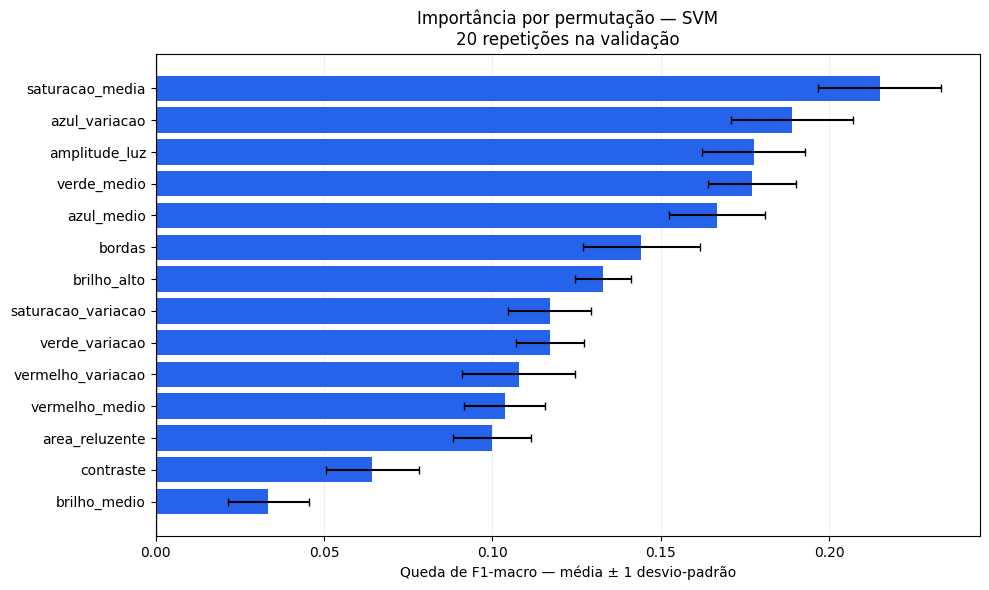

In [43]:
#@title Etapa 0.5 — importância por permutação (F1-macro, 20 repetições)
from sklearn.inspection import permutation_importance
from sklearn.utils.validation import check_is_fitted

_requeridas_05 = (
    "melhor_modelo_baseline", "melhor_f1_baseline", "nome_melhor_baseline",
    "X_valida", "y_valida", "COLUNAS_ORIGINAIS",
)
_faltantes_05 = [nome for nome in _requeridas_05 if nome not in globals()]
if _faltantes_05:
    raise RuntimeError(
        "Execute as etapas 0.1–0.4 nesta sessão antes da 0.5. Faltam: "
        + ", ".join(_faltantes_05)
    )
check_is_fitted(melhor_modelo_baseline)
assert tuple(X_valida.columns) == COLUNAS_ORIGINAIS

_previsoes_antes_05 = melhor_modelo_baseline.predict(X_valida)
f1_referencia_importancia = f1_score(
    y_valida, _previsoes_antes_05, average="macro", zero_division=0,
)
if not np.isclose(f1_referencia_importancia, melhor_f1_baseline):
    raise RuntimeError("O modelo ou a validação mudou desde a etapa 0.4; confira o baseline.")

N_REPETICOES_IMPORTANCIA = 20
# Em série: não requer subprocessos e é suficiente para os 14 descritores.
# Isso só controla recursos de execução, não a definição da análise.
N_JOBS_IMPORTANCIA = 1
resultado_importancia_baseline = permutation_importance(
    melhor_modelo_baseline,
    X_valida,
    y_valida,
    scoring="f1_macro",
    n_repeats=N_REPETICOES_IMPORTANCIA,
    random_state=42,
    n_jobs=N_JOBS_IMPORTANCIA,
)
tabela_importancia_baseline = pd.DataFrame({
    "feature": X_valida.columns,
    "importance_mean": resultado_importancia_baseline.importances_mean,
    "importance_std": resultado_importancia_baseline.importances_std,
}).sort_values("importance_mean", ascending=False, kind="stable").reset_index(drop=True)

# Guardar também cada repetição para inspeção posterior, sem arredondamento.
importancias_repeticoes_baseline = pd.DataFrame(
    resultado_importancia_baseline.importances,
    index=pd.Index(X_valida.columns, name="feature"),
    columns=[f"repeticao_{i+1:02d}" for i in range(N_REPETICOES_IMPORTANCIA)],
)
np.testing.assert_array_equal(
    _previsoes_antes_05, melhor_modelo_baseline.predict(X_valida),
)
assert np.isclose(f1_referencia_importancia, melhor_f1_baseline)
assert np.isfinite(tabela_importancia_baseline[["importance_mean", "importance_std"]]).all().all()

print(f"Modelo analisado: {nome_melhor_baseline}")
print(f"F1-macro de referência (sem embaralhar): {f1_referencia_importancia:.4f}")
print(f"Validação: {len(y_valida)} imagens; {N_REPETICOES_IMPORTANCIA} permutações por feature.")
display(tabela_importancia_baseline.round(5))

_top_importancias = tabela_importancia_baseline.head(14).iloc[::-1]
fig_importancia_baseline, ax_importancia_baseline = plt.subplots(figsize=(10, 6))
ax_importancia_baseline.barh(
    _top_importancias["feature"],
    _top_importancias["importance_mean"],
    xerr=_top_importancias["importance_std"],
    color=["#2563EB" if v > 0 else "#D97706" for v in _top_importancias["importance_mean"]],
    capsize=3,
)
ax_importancia_baseline.axvline(0, color="#475569", linewidth=1)
ax_importancia_baseline.set_xlabel("Queda de F1-macro — média ± 1 desvio-padrão")
ax_importancia_baseline.set_title(
    f"Importância por permutação — {nome_melhor_baseline}\n"
    f"{N_REPETICOES_IMPORTANCIA} repetições na validação"
)
ax_importancia_baseline.grid(axis="x", alpha=0.2)
ax_importancia_baseline.set_axisbelow(True)
fig_importancia_baseline.tight_layout()
plt.show()


In [44]:
#@title Etapa 0.5 — diagnóstico complementar e leitura do ranking
_classificador_importancia = (
    melhor_modelo_baseline.named_steps["model"]
    if isinstance(melhor_modelo_baseline, Pipeline)
    else melhor_modelo_baseline
)
# São medidas diferentes da queda de F1; não substituem a permutação.
importancia_interna_baseline = None
coeficientes_baseline = None
if isinstance(_classificador_importancia, RandomForestClassifier):
    importancia_interna_baseline = pd.DataFrame({
        "feature": X_valida.columns,
        "importance_impurity": _classificador_importancia.feature_importances_,
    }).sort_values("importance_impurity", ascending=False).reset_index(drop=True)
    print("Random Forest — redução de impureza no treino (não é queda de F1):")
    display(importancia_interna_baseline.round(5))
    print("Essa importância interna pode favorecer variáveis com muitos valores distintos.")
elif isinstance(_classificador_importancia, LogisticRegression):
    coeficientes_baseline = pd.DataFrame(
        _classificador_importancia.coef_.T,
        index=pd.Index(X_valida.columns, name="feature"),
        columns=_classificador_importancia.classes_,
    )
    print("Regressão Logística — coeficientes por classe, após o StandardScaler:")
    display(coeficientes_baseline.round(5))
    print("O sinal indica a direção no escore de cada classe; não indica causalidade.")
elif isinstance(_classificador_importancia, SVC):
    print(
        f"SVM com kernel {_classificador_importancia.kernel}: "
        "nesta análise, a interpretação principal é por permutação."
    )
    if _classificador_importancia.kernel == "rbf":
        print("O SVM RBF não fornece coeficientes lineares diretos das features.")

print("\nCinco maiores quedas médias de F1 ao embaralhar a feature:")
display(tabela_importancia_baseline.head(5).round(5))
_sem_queda_media = tabela_importancia_baseline.loc[
    tabela_importancia_baseline["importance_mean"] <= 0, "feature"
].tolist()
if _sem_queda_media:
    print("Sem queda média positiva nesta amostra:", ", ".join(_sem_queda_media))
else:
    print("Todas as features apresentaram queda média positiva nesta amostra.")
print("Esse resultado não equivale a um teste de remoção ou de significância.")
print("Etapa 0.5 concluída: baseline, 14 features e divisão de validação preservados.")
print(f"F1-macro do baseline permanece {melhor_f1_baseline:.4f}; nenhuma feature foi removida.")


SVM com kernel rbf: nesta análise, a interpretação principal é por permutação.
O SVM RBF não fornece coeficientes lineares diretos das features.

Cinco maiores quedas médias de F1 ao embaralhar a feature:


,feature,importance_mean,importance_std
0,saturacao_media,0.21502,0.01816
1,azul_variacao,0.18907,0.01810
2,amplitude_luz,0.17758,0.01525
3,verde_medio,0.17723,0.01308
4,azul_medio,0.16672,0.01411


Todas as features apresentaram queda média positiva nesta amostra.
Esse resultado não equivale a um teste de remoção ou de significância.
Etapa 0.5 concluída: baseline, 14 features e divisão de validação preservados.
F1-macro do baseline permanece 0.7266; nenhuma feature foi removida.


---
# 📈 BLOCO 4 · AVALIAR
## *Onde a máquina se confunde?*

> **Rosa:** *"O número agregado me diz pouco. Preciso saber quais pares de material ele
> confunde. Vidro classificado como plástico vai para a prensa e danifica o equipamento.
> Papel classificado como papelão só reduz um pouco o preço do lote."*

A observação identifica com precisão o limite de qualquer métrica escalar: ela agrega erros
de naturezas e custos distintos em um único número. A matriz de confusão preserva a
estrutura dos erros, e é ela que orienta decisões de engenharia.


           DESEMPENHO NO CONJUNTO DE VALIDAÇÃO
  Acurácia (acertos no geral) ..........  73.0%
  ⭐ F1-MACRO (métrica oficial) .........  72.7%
  Desempenho alto. Verifiquem a estabilidade entre execuções.


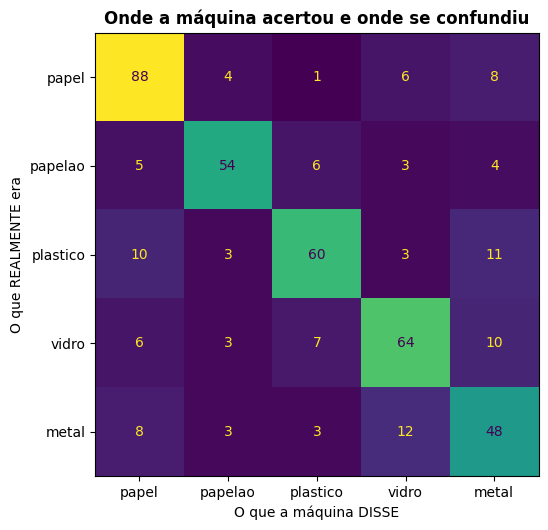


🔎 MAIORES CONFUSÕES DO MODELO:
   • 12 fotos de 🥫 METAL foram chamadas de 🍾 VIDRO
   • 11 fotos de 🧴 PLASTICO foram chamadas de 🥫 METAL
   • 10 fotos de 🧴 PLASTICO foram chamadas de 📄 PAPEL

   Analisem: quais descritores esses dois materiais compartilham, e que
   medida adicional permitiria separá-los?

              precision    recall  f1-score   support

       metal      0.593     0.649     0.619        74
       papel      0.752     0.822     0.786       107
     papelao      0.806     0.750     0.777        72
    plastico      0.779     0.690     0.732        87
       vidro      0.727     0.711     0.719        90

    accuracy                          0.730       430
   macro avg      0.731     0.724     0.727       430
weighted avg      0.734     0.730     0.731       430



In [45]:
#@title 🏆 O resultado da triagem automática { display-mode: "form" }
acuracia = accuracy_score(y_valida, previsoes)
f1 = f1_score(y_valida, previsoes, average="macro")

print("="*60)
print("           DESEMPENHO NO CONJUNTO DE VALIDAÇÃO")
print("="*60)
print(f"  Acurácia (acertos no geral) .......... {acuracia*100:5.1f}%")
print(f"  ⭐ F1-MACRO (métrica oficial) ......... {f1*100:5.1f}%")
print("="*60)
# Faixas calibradas nestes descritores: ~72% e o teto observado com boa configuração.
if   f1 >= .70: print("  Desempenho alto. Verifiquem a estabilidade entre execuções.")
elif f1 >= .64: print("  Desempenho sólido, com margem de otimização no Bloco 2.")
elif f1 >= .55: print("  Desempenho intermediário. Revisem o conjunto de características.")
else:           print("  Desempenho baixo. A representação atual não separa as classes.")

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ConfusionMatrixDisplay(confusion_matrix(y_valida, previsoes, labels=CLASSES),
    display_labels=CLASSES).plot(ax=ax, cmap="viridis", colorbar=False)
ax.set_title("Onde a máquina acertou e onde se confundiu", fontweight="bold")
ax.set_xlabel("O que a máquina DISSE"); ax.set_ylabel("O que REALMENTE era")
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_valida, previsoes, labels=CLASSES)
n = len(CLASSES)
confusoes = [(CLASSES[i], CLASSES[j], cm[i, j])
             for i in range(n) for j in range(n) if i != j and cm[i, j] > 0]
confusoes.sort(key=lambda t: -t[2])
print("\n🔎 MAIORES CONFUSÕES DO MODELO:")
if confusoes:
    for real, previsto, q in confusoes[:3]:
        print(f"   • {q} fotos de {EMOJI[real]} {real.upper()} "
              f"foram chamadas de {EMOJI[previsto]} {previsto.upper()}")
    print("\n   Analisem: quais descritores esses dois materiais compartilham, e que")
    print("   medida adicional permitiria separá-los?")
else:
    print("   Nenhuma! O modelo acertou todas as fotos do teste. 🎯")
print()
print(classification_report(y_valida, previsoes, digits=3))

if not padronizar and modelo_escolhido in ("Regressao Logistica", "SVM"):
    print("[!] O modelo escolhido é sensível à escala dos descritores e a")
    print("    padronização está DESLIGADA. Ligá-la no Bloco 2 costuma ser o")
    print("    ganho isolado mais relevante nesta trilha.")


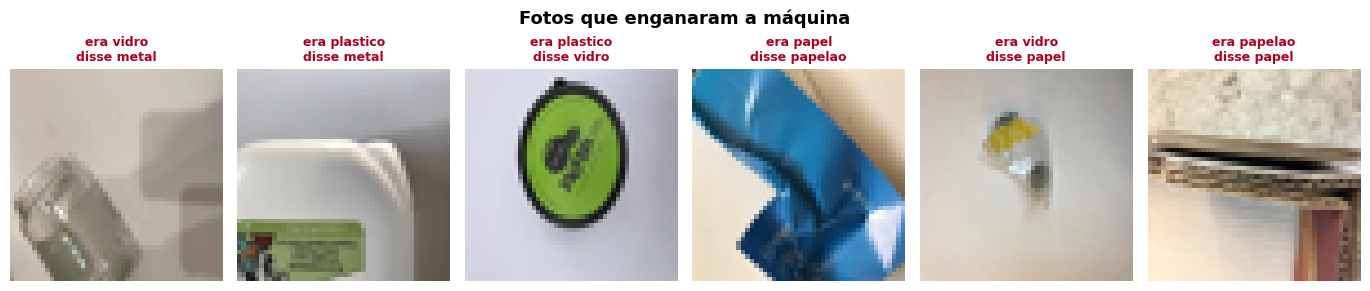

Classificações incorretas: 116 de 430 imagens.

A análise qualitativa de erros é prática padrão em visão computacional.
Examinem os casos acima e determinem:
   Um anotador humano classificaria essas imagens corretamente? Se não, o
   limite é da representação ou da própria qualidade do rótulo?
   Os erros compartilham alguma condição (baixa luminância, reflexo atípico)?
   Que descritor adicional capturaria a diferença que os atuais não capturam?


In [46]:
#@title 🕵️ A galeria dos erros { display-mode: "form" }
# A parte mais reveladora do desafio: **olhar as fotos que o modelo errou.**
idx_teste = X_valida.index.to_numpy()
y_valida_arr = np.asarray(y_valida)
errou = np.where(previsoes != y_valida_arr)[0]

if len(errou) == 0:
    print("🎯 Seu modelo não errou nenhuma foto do teste! Impressionante.")
else:
    n = min(6, len(errou))
    fig, axes = plt.subplots(1, n, figsize=(2.3*n, 3.1))
    if n == 1: axes = [axes]
    for ax, k in zip(axes, errou[:n]):
        ax.imshow(fotos[idx_teste[k]]); ax.axis("off")
        ax.set_title(f"era {y_valida_arr[k]}\ndisse {previsoes[k]}",
                     fontsize=9, color="#B00020", fontweight="bold")
    fig.suptitle("Fotos que enganaram a máquina", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()
    print(f"Classificações incorretas: {len(errou)} de {len(y_valida)} imagens.\n")
    print("A análise qualitativa de erros é prática padrão em visão computacional.")
    print("Examinem os casos acima e determinem:")
    print("   Um anotador humano classificaria essas imagens corretamente? Se não, o")
    print("   limite é da representação ou da própria qualidade do rótulo?")
    print("   Os erros compartilham alguma condição (baixa luminância, reflexo atípico)?")
    print("   Que descritor adicional capturaria a diferença que os atuais não capturam?")

---
# 🤔 PARADA OBRIGATÓRIA: uma conversa com a Dona Rosa

> **Rosa:** *"Tenho duas questões, e nenhuma delas é sobre o código de vocês."*
>
> *"A primeira é de governança. A cooperativa é autogestionária: as decisões passam por
> assembleia. Se eu levar uma ferramenta que altera o processo de trabalho, a assembleia
> vai perguntar quem decidiu implantá-la e sob quais condições. Sistemas assim costumam
> chegar prontos, decididos por quem não trabalha neles."*
>
> *"A segunda é econômica. Automação em triagem historicamente foi usada para reduzir
> postos, não para aliviar carga. A tecnologia não determina esse resultado, mas também não
> impede. Determina quem controla a implantação."*

### Questões para a equipe deliberar

1. **Deslocamento de domínio.** As imagens foram capturadas em um galpão específico, com
   iluminação e câmera específicas. Um modelo ajustado sobre esses descritores aprende, em
   parte, as condições da captura. Aplicado em outra cooperativa, com outra iluminação, o
   desempenho tende a cair mesmo com os mesmos materiais. Isso se chama **deslocamento de
   domínio** (*domain shift*) e é uma das principais causas de falha de sistemas de IA em
   produção. Como vocês testariam a exposição do modelo de vocês a esse risco, e o que
   fariam para mitigá-la?

2. **Autonomia da decisão.** Um sistema pode operar em modo autônomo, decidindo sozinho, ou
   em modo assistivo, sinalizando para decisão humana. Dada a taxa de erro que vocês
   mediram e o custo dos erros específicos que identificaram na matriz de confusão, qual
   dos dois regimes vocês recomendariam, e a partir de que desempenho a recomendação
   mudaria?

3. **Quem decide sobre a implantação.** A Rosa levanta uma questão que a literatura de
   tecnologia e trabalho trata há décadas: os efeitos da automação sobre o emprego dependem
   menos da técnica e mais de quem controla as decisões de implantação. Em uma cooperativa
   autogestionária, isso é decidido em assembleia. Que informação vocês precisariam entregar
   para que essa assembleia decidisse com autonomia real, e não apenas homologasse uma
   decisão técnica já tomada?

<img src="https://lh3.googleusercontent.com/d/11via5b3WO3iPrDtLkmXPWTynuAeHXGwt=w1600" width="100%"
     alt="Dois catadores trabalham na esteira ao lado de um braço robótico e de uma câmera com feixe ciano. No painel acima, ícones de lata, garrafa e papelão aparecem marcados como separados corretamente. Luz dourada de fim de tarde entra pela janela.">


In [47]:
#@title 📝 O relatório da sua equipe para a Dona Rosa { display-mode: "form" }
#@markdown Este texto vale nota e pode decidir o desempate.
nome_da_equipe = ""  #@param {type:"string"}
#@markdown **1. Quais características vocês usaram e por quê?**
resposta_1 = ""  #@param {type:"string"}
#@markdown **2. Quais materiais o modelo mais confundiu? Por que vocês acham que isso acontece?**
resposta_2 = ""  #@param {type:"string"}
#@markdown **3. Regime de operação recomendado (autônomo ou assistivo) e justificativa.**
resposta_3 = ""  #@param {type:"string"}

relatorio = {"equipe": nome_da_equipe, "modelo": modelo_escolhido,
             "caracteristicas": conjunto_de_caracteristicas, "padronizar": padronizar,
             "C": forca_C, "teste_pct": tamanho_da_validacao,
             "f1_macro": round(f1, 4), "acuracia": round(acuracia, 4),
             "just_caracteristicas": resposta_1, "just_confusoes": resposta_2,
             "just_impacto": resposta_3}
faltando = [k for k in ["equipe", "just_caracteristicas", "just_confusoes", "just_impacto"]
            if not relatorio[k].strip()]
if faltando:
    print("⚠️ Ainda faltam campos:", ", ".join(faltando))
else:
    print("Relatório completo. Prossigam para a submissão.")

⚠️ Ainda faltam campos: equipe, just_caracteristicas, just_confusoes, just_impacto


In [48]:
#@title 🚀 Gerar o arquivo de submissão (opcional; opção manual)
gerar_submissao = False  #@param {type:"boolean"}
if not gerar_submissao:
    print("Submissão não gerada: experimentos incrementais. Ative apenas quando for enviar.")
else:
    #@title 🚀 Gerar o arquivo de submissão { display-mode: "form" }
    #@markdown Rode a célula (▶). Os dois arquivos são baixados automaticamente.
    import json, pathlib
    
    PASTA_SUBMISSAO = pathlib.Path("submissoes/visao")
    PASTA_SUBMISSAO.mkdir(parents=True, exist_ok=True)
    if "relatorio" not in dir() or not isinstance(relatorio, dict):
        relatorio = {"equipe": "", "modelo": modelo_escolhido,
                     "caracteristicas": conjunto_de_caracteristicas, "padronizar": padronizar,
                     "C": forca_C, "teste_pct": tamanho_da_validacao,
                     "f1_macro": round(f1, 4), "acuracia": round(acuracia, 4),
                     "just_caracteristicas": "", "just_confusoes": "", "just_impacto": ""}
    
    X_final = (X_melhor_teste if "X_melhor_teste" in globals() else X_caract_teste)[colunas]
    palpites = modelo.predict(X_final)
    submissao = pd.DataFrame({"id_foto": np.arange(len(palpites)),
                              "material_previsto": palpites})
    
    assert len(submissao) == N_TESTE, f"A submissão precisa ter {N_TESTE} linhas."
    csv_saida = PASTA_SUBMISSAO / "submissao_visao.csv"
    json_saida = PASTA_SUBMISSAO / "relatorio_visao.json"
    submissao.to_csv(csv_saida, index=False)
    with open(json_saida, "w", encoding="utf-8") as f:
        json.dump(relatorio, f, ensure_ascii=False, indent=2)
    
    print("="*60)
    print("             ARQUIVOS PRONTOS PARA ENVIO")
    print("="*60)
    print(f"  submissao_visao.csv   ({len(submissao)} linhas)")
    print("  relatorio_visao.json")
    print("="*60)
    print("\n  Distribuição prevista no teste:")
    for k, v in pd.Series(palpites).value_counts().items():
        print(f"     {EMOJI[k]} {k:<10} {v:>4}")
    
    try:
        from google.colab import files
        files.download(str(csv_saida))
        files.download(str(json_saida))
        print("\n  Download iniciado. Enviem os dois arquivos na plataforma.")
    except ImportError:
        print(f"\n  Fora do Colab: os arquivos estão em {PASTA_SUBMISSAO.resolve()}")


Submissão não gerada: experimentos incrementais. Ative apenas quando for enviar.


---
# 🌟 FIM DA MISSÃO RECOMEÇO

> **Rosa:** *"Levamos a proposta de vocês à assembleia. Aprovamos em regime assistivo: a
> máquina sinaliza, a pessoa confirma. Foi a recomendação de vocês e foi também o que a
> assembleia entendeu como aceitável."*
>
> *"O primeiro lote saiu sem contaminação e recebemos o valor integral. Mas o que fez
> diferença na discussão não foi o número de acerto. Foi vocês terem descrito onde o modelo
> falha e sob quais condições ele deixa de valer. Isso permitiu decidir com informação."*

---

### Competências desenvolvidas neste desafio

- O problema da representação em dados não estruturados
- Extração de características e redução de dimensionalidade
- A separação entre representação e classificação como princípio de projeto
- O papel do conhecimento de domínio na engenharia de atributos
- Sensibilidade de algoritmos à escala das variáveis, e quando padronizar
- `Pipeline` como mecanismo de disciplina no ajuste de transformações
- Análise qualitativa de erros e leitura estrutural da matriz de confusão
- Deslocamento de domínio como causa de falha em produção
- Regimes de autonomia e governança de sistemas automatizados

**Otimização.** Alterem **um fator por vez** e registrem o efeito: conjunto de
características, algoritmo, padronização, valor de C. Comparações válidas exigem isolar a
variável manipulada.
